# Interactive demo: constructing oriented hierarchies

This notebook runs the two implementations of the repository on the bundled data:

- **`new_algorithm`** (`new_algorithm.py`): selection of directed pairs with a heap, then ordered classes built by graph traversal with cycle rejection;
- **`optimized_algorithm`** (`optimized_algorithm.py`): thresholded implication graph, reachability sets, classes ordered by inclusion, then filtering of partially overlapping classes.

Both come from statistical implicative analysis (SIA). The functions are gathered in `hierarchy_algorithms.py`; the scripts remain the reference.

Run the cells from top to bottom (menu *Runtime → Run all* on Colab). Running times depend on the machine.

In [1]:
# Setup: get the repository code and data if the notebook is opened outside the repo (e.g. on Colab)
import os, subprocess, zipfile

REPO = "A-fast-algorithm-for-constructing-an-oriented-hierarchy"
URL = "https://github.com/Fidy-Heritiana/" + REPO + ".git"

if not os.path.exists("hierarchy_algorithms.py"):
    subprocess.run(["git", "clone", URL], check=True)
    os.chdir(REPO)

if not os.path.exists("animales_sec1.csv"):
    with zipfile.ZipFile("Data.zip") as z:
        z.extractall(".")

print("Repository code and data ready.")

Repository code and data ready.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import hierarchy_algorithms as ha

## 1. Choose a dataset and the thresholds

`fichier` is `animales_sec1.csv` (41 observations, 31 variables) or one of `simulation_1.csv` to `simulation_20.csv` (10 to 200 variables). The defaults of the scripts are `alpha_new = 0.5` (scores **at least** `alpha` are kept) and `alpha_opt = 0.7` (scores **strictly greater** than `alpha` are kept).

In [3]:
fichier = "animales_sec1.csv"
alpha_new = 0.5
alpha_opt = 0.7

df = pd.read_csv(fichier)
print(fichier, ":", df.shape[0], "observations,", df.shape[1], "variables")
df.iloc[:, :8].head()

animales_sec1.csv : 41 observations, 31 variables


,amoroso,agresivo,atractivo,hermoso,bete,bueno,ruidoso,colores
0,0,1,1,1,1,0,0,1
1,0,0,0,0,1,0,0,1
2,0,0,1,0,0,0,1,0
3,0,0,1,1,1,1,0,1
4,0,1,0,1,0,0,0,0


## 2. Run both algorithms

Each algorithm uses its own score convention, as in the scripts: the score is 0 when `n_y = n` for `new_algorithm`, and when `n_x > n_y` for `optimized_algorithm`. The matrices are built with `matrice_implication_rapide`, which gives exactly the same values as the loops of the scripts, much faster. The times below are those of the algorithms alone, without the matrix.

In [4]:
mat_new = ha.matrice_implication_rapide(df, "new")
mat_opt = ha.matrice_implication_rapide(df, "optimized")

classes_new, t_new = ha.chronometre(ha.new_algorithm, mat_new, alpha_new)
(G, classes_opt), t_opt = ha.chronometre(ha.optimized_algorithm, mat_opt, alpha_opt)

def au_moins_2(classes):
    return [c for c in classes if len(c) >= 2]

print(f"new_algorithm       : {len(classes_new)} classes returned ({len(au_moins_2(classes_new))} with at least 2 variables) in {t_new:.3f} s")
print(f"optimized_algorithm : {len(classes_opt)} classes returned ({len(au_moins_2(classes_opt))} with at least 2 variables) in {t_opt:.3f} s")

new_algorithm       : 31 classes returned (31 with at least 2 variables) in 0.018 s
optimized_algorithm : 45 classes returned (14 with at least 2 variables) in 0.021 s


## 3. The classes with at least two variables

A class of `new_algorithm` is an *ordered* chain of variables. A class of `optimized_algorithm` is listed with its variables sorted.

In [5]:
def afficher(classes, titre, maxi=12, fleche=" → "):
    liste = au_moins_2(classes)
    print(f"{titre} ({len(liste)} classes with at least 2 variables)")
    for c in liste[:maxi]:
        print("  ", fleche.join(str(v) for v in c))
    if len(liste) > maxi:
        print(f"   ... and {len(liste) - maxi} more")

afficher(classes_new, "new_algorithm")
print()
afficher(classes_opt, "optimized_algorithm", fleche=", ")

new_algorithm (31 classes with at least 2 variables)
   atractivo → mortal
   feo → franco
   misterioso → pegajoso
   largo → negro
   fuerte → bete
   gordo → atractivo
   gordo → atractivo → mortal
   colores → temeroso
   negro → suave
   largo → negro → suave
   hermoso → despreocupado
   inteligente → largo
   ... and 19 more

optimized_algorithm (14 classes with at least 2 variables)
   peligroso, suave
   feroz, peligroso
   amoroso, duro
   majestuoso, mortal
   bete, fuerte
   atractivo, gordo
   misterioso, pegajoso
   feo, franco
   despreocupado, hermoso
   agresivo, extravagante
   inteligente, largo
   despacio, niza
   ... and 2 more


## 4. Implication graph (optimized algorithm)

There is an arrow i → j when the implication score of i ⇒ j is greater than `alpha_opt`.

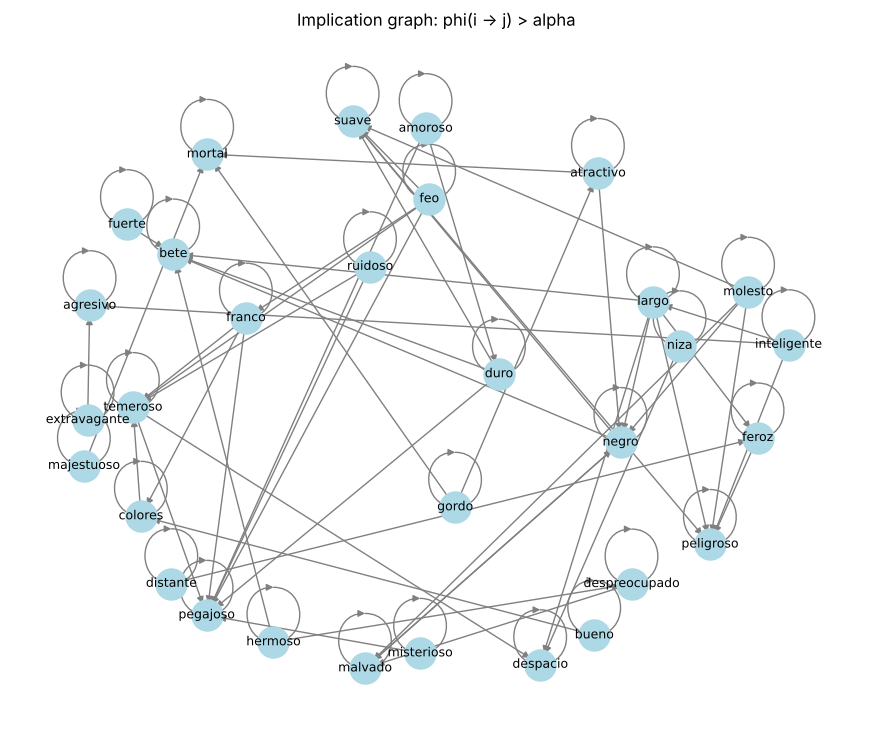

In [6]:
if 0 < G.number_of_nodes() <= 40:
    ha.dessiner_graphe(G, ax=plt.subplots(figsize=(11, 9))[1], taille_noeuds=500, taille_police=9, poids=G.number_of_edges() <= 30)
    plt.show()
elif G.number_of_nodes() == 0:
    print("No arrow for this threshold: try a smaller alpha_opt.")
else:
    print(f"The graph has {G.number_of_nodes()} vertices: too many to draw here. Try a smaller dataset.")

## 5. A controlled comparison: same convention, same threshold

With each algorithm's own convention and threshold the two outputs are not meant to be identical. For a controlled comparison, choose **one** score convention (`"new"` or `"optimized"`) and the same thresholds. The two scripts still differ in their threshold test (`>=` for `new_algorithm`, `>` for `optimized_algorithm`); this is kept as is. Classes are compared as sets of variables, order ignored.

In [7]:
convention = "optimized"        # or "new"
mat = ha.matrice_implication_rapide(df, convention)

lignes = []
for a in [0.5, 0.6, 0.7, 0.8, 0.9]:
    cn = ha.new_algorithm(mat, a)
    _, co = ha.optimized_algorithm(mat, a)
    en, eo = ha.classes_comme_ensembles(cn), ha.classes_comme_ensembles(co)
    union = en | eo
    lignes.append({
        "alpha": a,
        "new_algorithm": len(en),
        "optimized_algorithm": len(eo),
        "same sets of variables": len(en & eo),
        "Jaccard": round(len(en & eo) / len(union), 2) if union else None,
    })

pd.DataFrame(lignes)

,alpha,new_algorithm,optimized_algorithm,same sets of variables,Jaccard
0,0.5,31,7,0,0.00
1,0.6,28,8,2,0.06
2,0.7,26,14,8,0.25
3,0.8,18,15,8,0.32
4,0.9,7,9,7,0.78


## 6. Running time against the number of variables

Time of the algorithms alone on `simulation_1.csv` to `simulation_10.csv` (10 to 100 variables), each with its own convention and the thresholds chosen above.

,variables,new_algorithm (s),optimized_algorithm (s)
0,10,0.0016,0.0019
1,20,0.0058,0.0073
2,30,0.0132,0.0152
3,40,0.0226,0.0297
4,50,0.0916,0.0476
5,60,0.0512,0.0970
6,70,0.0723,0.1447
7,80,0.0985,0.2741
8,90,0.1540,0.3260
9,100,0.2186,0.6463


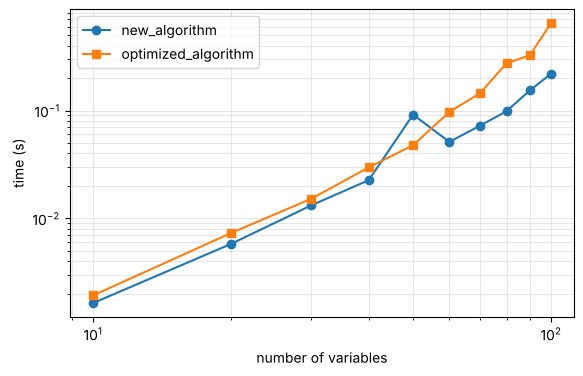

new_algorithm (s): fitted exponent k = 2.13 in T(n) ~ n^k (datasets from the third one)
optimized_algorithm (s): fitted exponent k = 3.06 in T(n) ~ n^k (datasets from the third one)


In [8]:
lignes = []
for k in range(1, 11):
    d = pd.read_csv(f"simulation_{k}.csv")
    _, tn = ha.chronometre(ha.new_algorithm, ha.matrice_implication_rapide(d, "new"), alpha_new)
    _, to = ha.chronometre(ha.optimized_algorithm, ha.matrice_implication_rapide(d, "optimized"), alpha_opt)
    lignes.append({"variables": d.shape[1], "new_algorithm (s)": tn, "optimized_algorithm (s)": to})

temps = pd.DataFrame(lignes)
display(temps.round(4))

plt.figure(figsize=(6.5, 4))
plt.loglog(temps["variables"], temps["new_algorithm (s)"], marker="o", label="new_algorithm")
plt.loglog(temps["variables"], temps["optimized_algorithm (s)"], marker="s", label="optimized_algorithm")
plt.xlabel("number of variables")
plt.ylabel("time (s)")
plt.legend()
plt.grid(alpha=0.3, which="both")
plt.show()

x = np.log(temps["variables"].values[2:])
for c in ("new_algorithm (s)", "optimized_algorithm (s)"):
    k = np.polyfit(x, np.log(temps[c].values[2:]), 1)[0]
    print(f"{c}: fitted exponent k = {k:.2f} in T(n) ~ n^k (datasets from the third one)")

## 7. Interactive version

Choose a dataset and the thresholds, then press the button. Buttons and sliders do not display in the GitHub preview: open this notebook on Colab or Binder to use them.

In [ ]:
def run_demo(fichier="animales_sec1.csv", alpha_new=0.5, alpha_opt=0.7):
    d = pd.read_csv(fichier)
    cn, tn = ha.chronometre(ha.new_algorithm, ha.matrice_implication_rapide(d, "new"), alpha_new)
    (GG, co), to = ha.chronometre(ha.optimized_algorithm, ha.matrice_implication_rapide(d, "optimized"), alpha_opt)
    print(f"{fichier}: {d.shape[0]} observations, {d.shape[1]} variables")
    print(f"new_algorithm       : {len(cn)} classes in {tn:.3f} s")
    print(f"optimized_algorithm : {len(co)} classes in {to:.3f} s")
    if 0 < GG.number_of_nodes() <= 40:
        ha.dessiner_graphe(GG, ax=plt.subplots(figsize=(9, 7))[1], taille_noeuds=400, taille_police=8, poids=GG.number_of_edges() <= 30)
        plt.show()


try:
    from ipywidgets import interact_manual, Dropdown, FloatSlider
    fichiers = ["animales_sec1.csv"] + [f"simulation_{k}.csv" for k in range(1, 21)]
    interact_manual(
        run_demo,
        fichier=Dropdown(options=fichiers, value="animales_sec1.csv"),
        alpha_new=FloatSlider(min=0.5, max=0.99, step=0.01, value=0.5),
        alpha_opt=FloatSlider(min=0.5, max=0.99, step=0.01, value=0.7),
    )
except ImportError:
    run_demo()